<center><h1>Wang_Selena_HW5</h1></center>
<br>
<br>

Name: Selena Wang
<br>
Github Username: slnwang
<br>
USC ID: 6791950498

## 1. Decision Trees as Interpretable Models

Import packages

In [2]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 2.6/48.9 MB 12.7 MB/s eta 0:00:04
   ------ --------------------------------- 7.9/48.9 MB 18.6 MB/s eta 0:00:03
   ---------- ----------------------------- 13.4/48.9 MB 20.9 MB/s eta 0:00:02
   -------------- ------------------------- 17.3/48.9 MB 20.4 MB/s eta 0:00:02
   ----------------- ---------------------- 21.2/48.9 MB 20.1 MB/s eta 0:00:02
   -------------------- ------------------- 25.4/48.9 MB 20.2 MB/s eta 0:00:02
   ------------------------ --------------- 30.1/48.9 MB 20.5 MB/s eta 0:00:01
   ---------------------------- ----------- 35.4/48.9 MB 21.2 MB/s eta 0:00:01
   --------------------------------- ------ 40.6/48.9 MB 21.6 MB/s eta 0:00:01
   ------------------------------------- -- 45.6/48.9 MB 21.9 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 21.8 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor


### (a) Obtain Data

Get the Accute Inamations Data Set

In [18]:
columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pains",
    "Urethra_Burning",
    "Bladder_Inflammation",
    "Nephritis"
]

df = pd.read_csv("../data/diagnosis.data", sep = "\t", header = None, 
                 names = columns, encoding = "utf-16", decimal = ",")
df = df.replace({"yes": 1, "no": 0})

df.head()


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Urethra_Burning,Bladder_Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

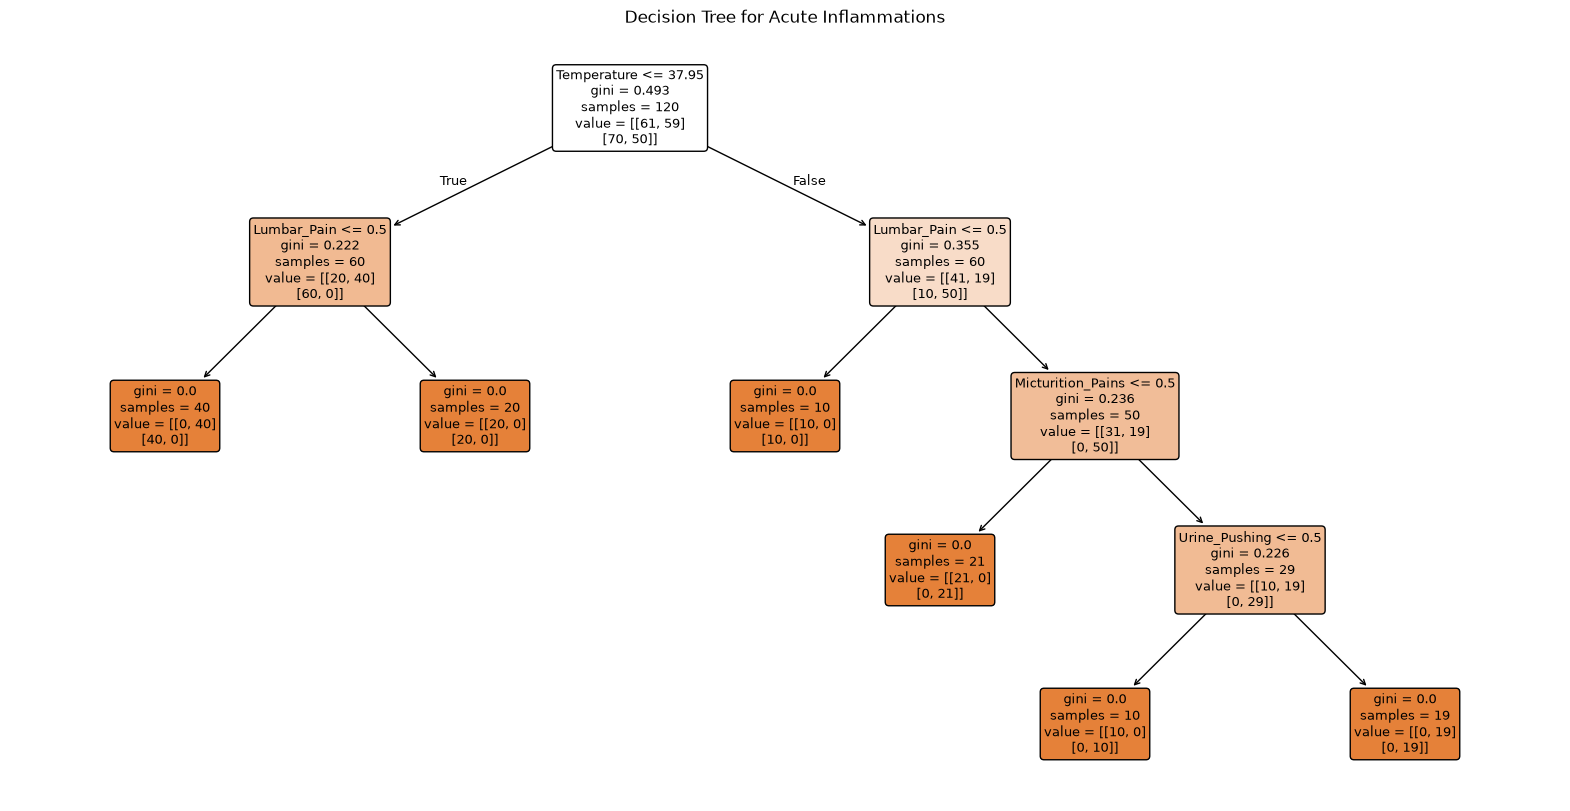

In [20]:
X = df.iloc[:, :-2].apply(pd.to_numeric)
y = df.iloc[:, -2:].astype(int)

dt = DecisionTreeClassifier(random_state = 31)
dt.fit(X, y)

plt.figure(figsize=(20, 10))
plot_tree(dt, feature_names = X.columns, class_names = ["No", "Yes"], 
          filled = True, rounded = True, fontsize = 9)

plt.title("Decision Tree for Acute Inflammations")
plt.show()

### (c) Convert the decision rules

In [17]:
rules = export_text(dt, feature_names = list(X.columns))

print(rules)

|--- Temperature <= 37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 1
|   |--- Lumbar_Pain >  0.50
|   |   |--- class: 0
|--- Temperature >  37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 0
|   |--- Lumbar_Pain >  0.50
|   |   |--- Micturition_Pains <= 0.50
|   |   |   |--- class: 0
|   |   |--- Micturition_Pains >  0.50
|   |   |   |--- Urine_Pushing <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Urine_Pushing >  0.50
|   |   |   |   |--- class: 0



### (d) Cost-complexity pruning

In [21]:
path = dt.cost_complexity_pruning_path(X, y)

ccp_alphas = path.ccp_alphas

print("Candidate alpha values:")
print(ccp_alphas)

cv = KFold(n_splits = 5, shuffle = True, random_state = 31)
cv_scores = []

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(
        random_state = 31,
        ccp_alpha = alpha
    )

    scores = cross_val_score(tree, X, y, cv = cv, scoring = "accuracy")
    cv_scores.append(scores.mean())

pruning_results = pd.DataFrame({"ccp_alpha": ccp_alphas, "CV_Accuracy": cv_scores})

print(pruning_results)

Candidate alpha values:
[0.         0.04908333 0.07947222 0.11111111 0.20423611]
   ccp_alpha  CV_Accuracy
0   0.000000     1.000000
1   0.049083     0.883333
2   0.079472     0.783333
3   0.111111     0.658333
4   0.204236     0.316667


Selected alpha: 0.0
Best CV accuracy: 1.0


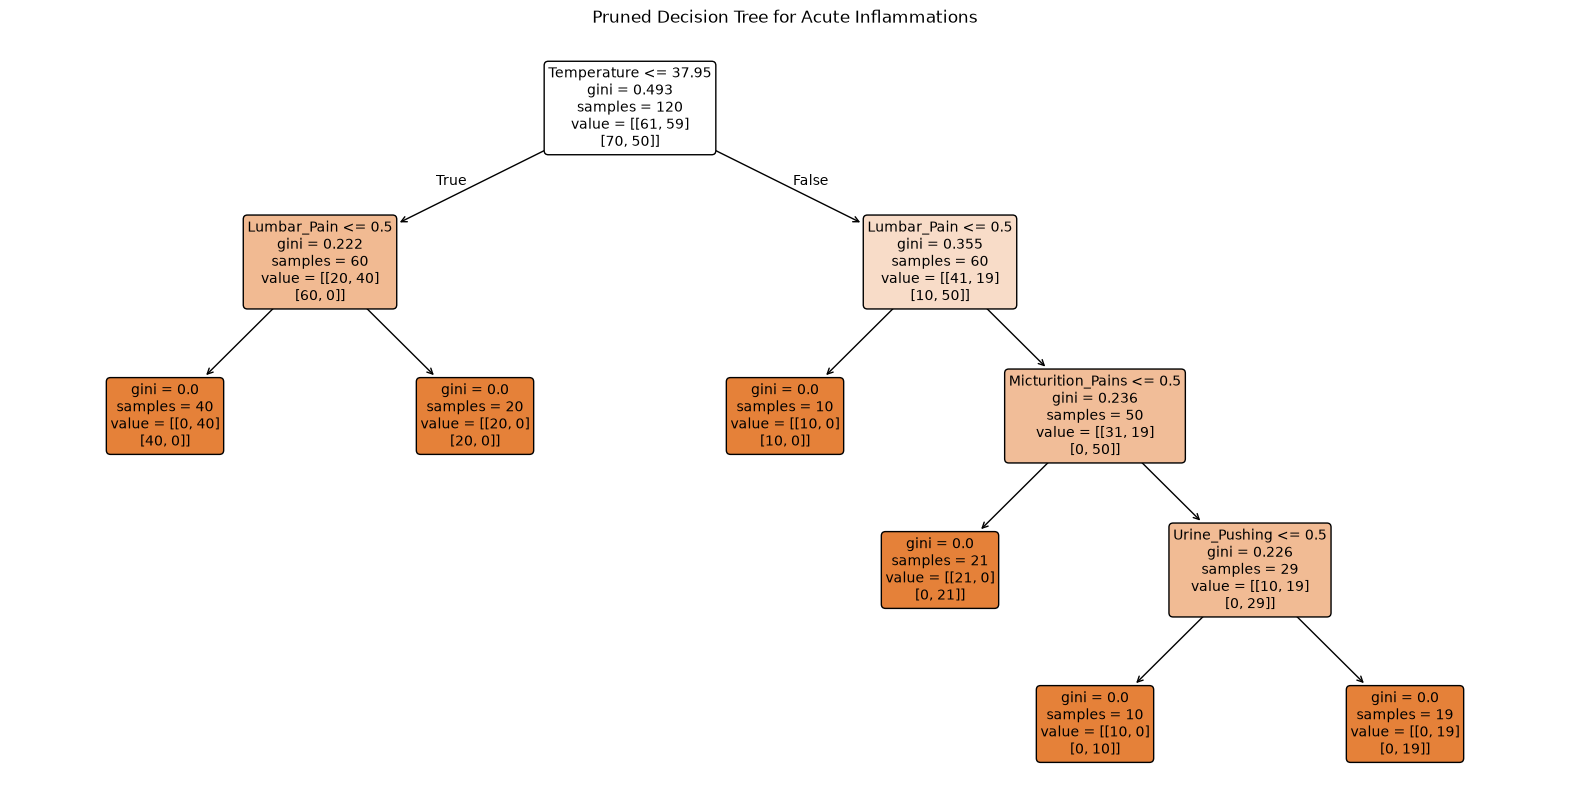

In [26]:
best_score = pruning_results["CV_Accuracy"].max()

best_alphas = pruning_results.loc[np.isclose(pruning_results["CV_Accuracy"], best_score), "ccp_alpha"]

candidates = []

for alpha in best_alphas:
    tree = DecisionTreeClassifier(random_state = 31, ccp_alpha = alpha)
    tree.fit(X, y)

    candidates.append({
        "ccp_alpha": alpha,
        "Leaves": tree.get_n_leaves(),
        "Depth": tree.get_depth()
    })

candidates = pd.DataFrame(candidates)

best_alpha = candidates.sort_values(["Leaves", "Depth", "ccp_alpha"], 
                                    ascending=[True, True, False]).iloc[0]["ccp_alpha"]

print("Selected alpha:", best_alpha)
print("Best CV accuracy:", best_score)

pruned_dt = DecisionTreeClassifier(random_state=31, ccp_alpha=best_alpha)

pruned_dt.fit(X, y)

plt.figure(figsize = (20, 10))
plot_tree(pruned_dt, feature_names = X.columns, filled = True, rounded = True, fontsize = 10)

plt.title("Pruned Decision Tree for Acute Inflammations")
plt.show()



Best alpha is the same as the original tree. try next one to produce a more minimal tree. Less accurate but more minimal and interpretable.

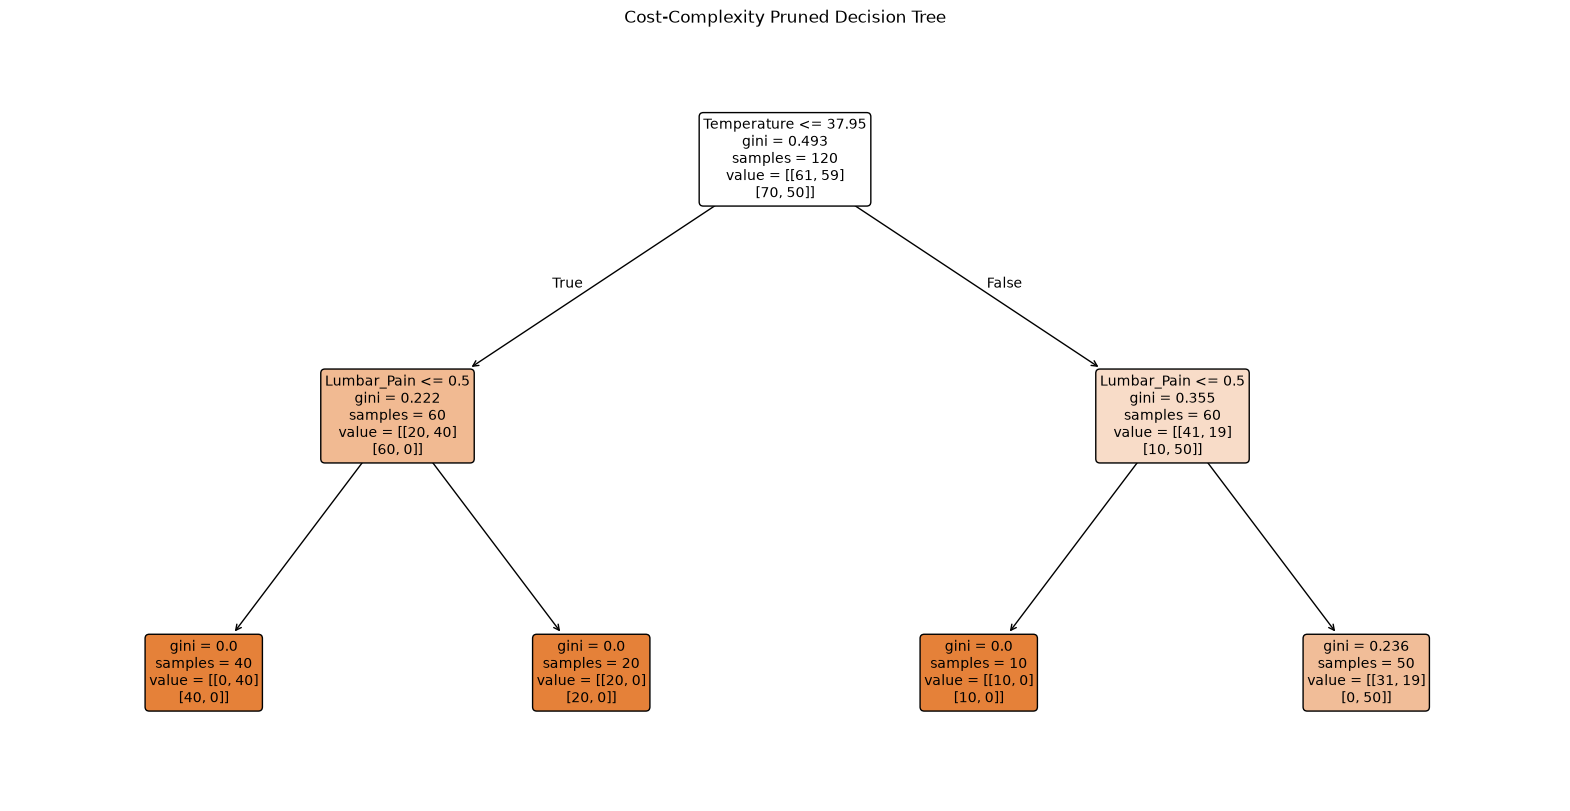

Depth: 2
Leaves: 4
Training accuracy: 0.8416666666666667


In [30]:
pruned_dt = DecisionTreeClassifier(random_state = 31, ccp_alpha = ccp_alphas[1])

pruned_dt.fit(X, y)

plt.figure(figsize = (20, 10))
plot_tree(pruned_dt, feature_names = X.columns, filled = True, rounded = True, fontsize = 10)

plt.title("Cost-Complexity Pruned Decision Tree")
plt.show()

print("Depth:", pruned_dt.get_depth())
print("Leaves:", pruned_dt.get_n_leaves())
print("Training accuracy:", pruned_dt.score(X, y))

In [31]:
rules = export_text(pruned_dt, feature_names = list(X.columns))

print(rules)

comparison = pd.DataFrame({
    "Model": ["Original Tree", "Pruned Tree"],
    "Depth": [dt.get_depth(), pruned_dt.get_depth()],
    "Leaves": [dt.get_n_leaves(), pruned_dt.get_n_leaves()],
    "Training Accuracy": [
        dt.score(X, y),
        pruned_dt.score(X, y)
    ]
})

print(comparison)


|--- Temperature <= 37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 1
|   |--- Lumbar_Pain >  0.50
|   |   |--- class: 0
|--- Temperature >  37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 0
|   |--- Lumbar_Pain >  0.50
|   |   |--- class: 0

           Model  Depth  Leaves  Training Accuracy
0  Original Tree      4       6           1.000000
1    Pruned Tree      2       4           0.841667


Cost-complexity pruning was used to simplify the original decision tree. With `ccp_alpha = 0.049083`, the tree depth decreased from 4 to 2, and the number of leaves decreased from 6 to 4.

The training accuracy decreased from 1.0 to 0.8417, with a cross-validation accuracy of 0.8833. The pruned tree only uses Temperature and Lumbar Pain, reducing the number of IF-THEN rules from 6 to 4.

Although the pruned tree has lower accuracy, it is easier to interpret because it uses fewer features and decision rules. The original tree performed better in cross-validation, but the pruned tree provides a simpler alternative.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [41]:
crime_df = pd.read_csv("../data/communities.data", header = None, na_values = "?")

print("Dataset shape:", crime_df.shape)

with open("../data/communities.names", "r") as file:
    columns = [
        line.split()[1]
        for line in file
        if line.startswith("@attribute")
    ]

crime_df.columns = columns
print(crime_df.head())

train_df = crime_df.iloc[:1495]
test_df = crime_df.iloc[1495:]

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

Dataset shape: (1994, 128)
   state  county  community        communityname  fold  population  \
0      8     NaN        NaN         Lakewoodcity     1        0.19   
1     53     NaN        NaN          Tukwilacity     1        0.00   
2     24     NaN        NaN         Aberdeentown     1        0.00   
3     34     5.0    81440.0  Willingborotownship     1        0.04   
4     42    95.0     6096.0    Bethlehemtownship     1        0.01   

   householdsize  racepctblack  racePctWhite  racePctAsian  ...  LandArea  \
0           0.33          0.02          0.90          0.12  ...      0.12   
1           0.16          0.12          0.74          0.45  ...      0.02   
2           0.42          0.49          0.56          0.17  ...      0.01   
3           0.77          1.00          0.08          0.12  ...      0.02   
4           0.55          0.02          0.95          0.09  ...      0.04   

   PopDens  PctUsePubTrans  PolicCars  PolicOperBudg  LemasPctPolicOnPatr  \
0     0.26  

### (b) Missing values

In [44]:
non_predictive = ["state", "county", "community", "communityname", "fold"]

train_df = crime_df.iloc[:1495].drop(columns=non_predictive)
test_df = crime_df.iloc[1495:].drop(columns=non_predictive)

X_train = train_df.drop(columns=["ViolentCrimesPerPop"])
y_train = train_df["ViolentCrimesPerPop"]

X_test = test_df.drop(columns=["ViolentCrimesPerPop"])
y_test = test_df["ViolentCrimesPerPop"]

missing = X_train.isnull().sum()

print("Features with missing values:")
print(missing[missing > 0].sort_values(ascending=False))

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\nTraining missing values:", X_train.isnull().sum().sum())
print("Test missing values:", X_test.isnull().sum().sum())

print("\nTraining shape:", X_train.shape)
print("Test shape:", X_test.shape)


Features with missing values:
LemasSwornFT            1256
LemasSwFTPerPop         1256
LemasSwFTFieldOps       1256
LemasTotalReq           1256
LemasSwFTFieldPerPop    1256
LemasTotReqPerPop       1256
PolicReqPerOffic        1256
OfficAssgnDrugUnits     1256
PolicPerPop             1256
RacialMatchCommPol      1256
PctPolicWhite           1256
PctPolicBlack           1256
PctPolicHisp            1256
PctPolicAsian           1256
PctPolicMinor           1256
PolicOperBudg           1256
NumKindsDrugsSeiz       1256
PolicAveOTWorked        1256
PolicCars               1256
LemasGangUnitDeploy     1256
LemasPctPolicOnPatr     1256
PolicBudgPerPop         1256
OtherPerCap                1
dtype: int64

Training missing values: 0
Test missing values: 0

Training shape: (1495, 122)
Test shape: (499, 122)


### (c) Plot a correlation matrix

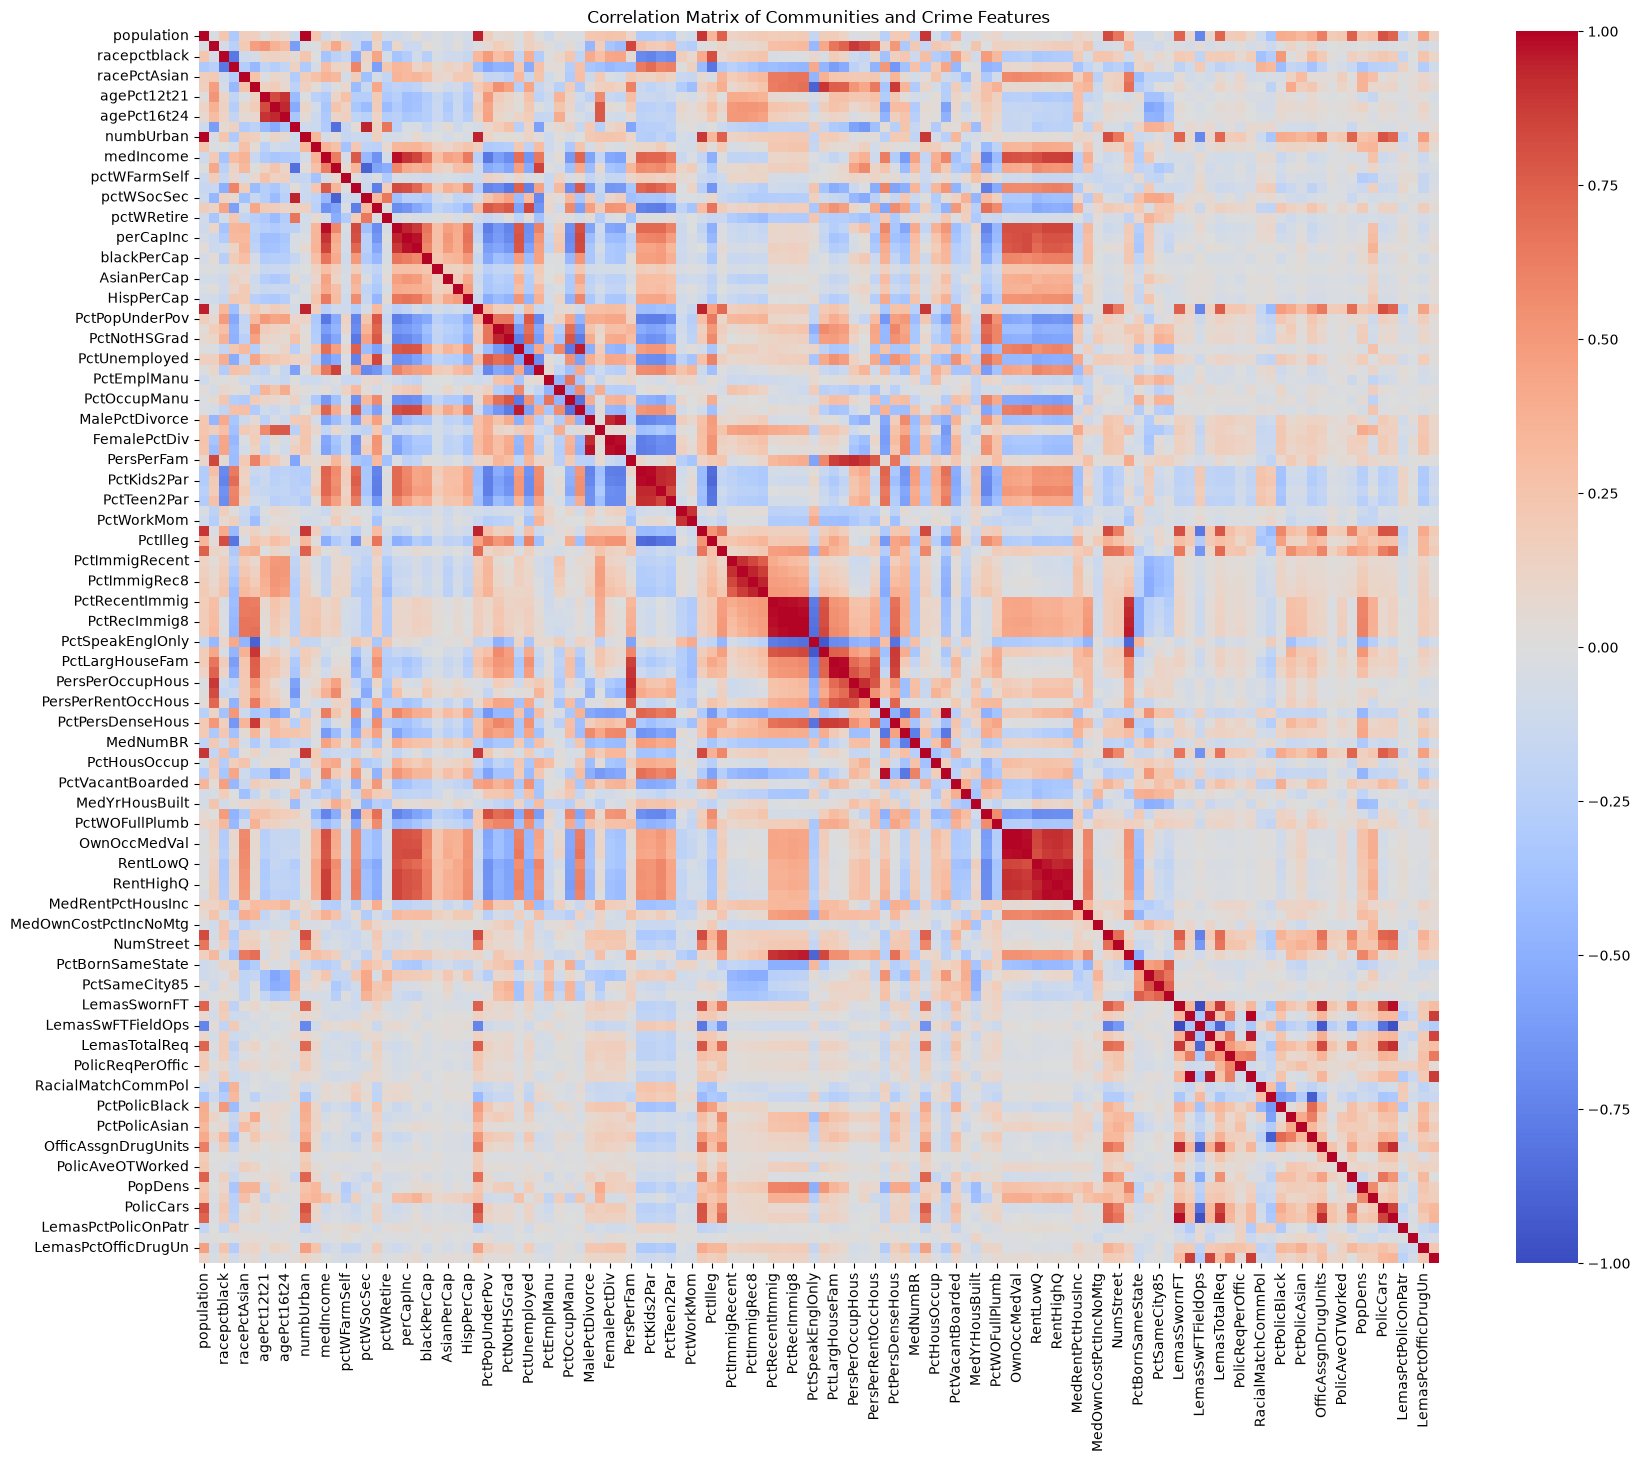

In [45]:
corr_matrix = X_train.corr()

plt.figure(figsize = (20, 16))
sns.heatmap(corr_matrix, cmap = "coolwarm", vmin = -1, vmax = 1, center = 0)

plt.title("Correlation Matrix of Communities and Crime Features")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [46]:
cv = X_train.std(ddof=1) / X_train.mean()

cv_df = pd.DataFrame({"Feature": cv.index, "CV": cv.values}).sort_values(by="CV", ascending=False)

print(cv_df.to_string(index=False))


              Feature       CV
        PctPolicAsian 5.527059
            NumStreet 4.292923
        NumInShelters 3.470952
             NumIlleg 3.058964
             NumImmig 2.926635
  LemasPctOfficDrugUn 2.552946
          NumUnderPov 2.342443
         LemasSwornFT 2.248042
           population 2.241105
            numbUrban 2.038461
           HousVacant 1.968467
        PolicOperBudg 1.645508
             LandArea 1.645408
          racePctHisp 1.612091
  PctNotSpeakEnglWell 1.456618
        LemasTotalReq 1.451887
         racepctblack 1.428885
       PctUsePubTrans 1.397110
         racePctAsian 1.359100
         PctPolicHisp 1.353882
       PctRecentImmig 1.288287
         PctRecImmig5 1.286184
        PctRecImmig10 1.270476
         PctRecImmig8 1.265579
  OfficAssgnDrugUnits 1.174565
     PctPersDenseHous 1.132926
            PolicCars 1.112831
       PctForeignBorn 1.065880
     PctVacantBoarded 1.054827
       PctHousNoPhone 0.922765
             PctIlleg 0.921550
        

### (e) Scatter plots and box plots for highest CV features

            Feature       CV
      PctPolicAsian 5.527059
          NumStreet 4.292923
      NumInShelters 3.470952
           NumIlleg 3.058964
           NumImmig 2.926635
LemasPctOfficDrugUn 2.552946
        NumUnderPov 2.342443
       LemasSwornFT 2.248042
         population 2.241105
          numbUrban 2.038461
         HousVacant 1.968467


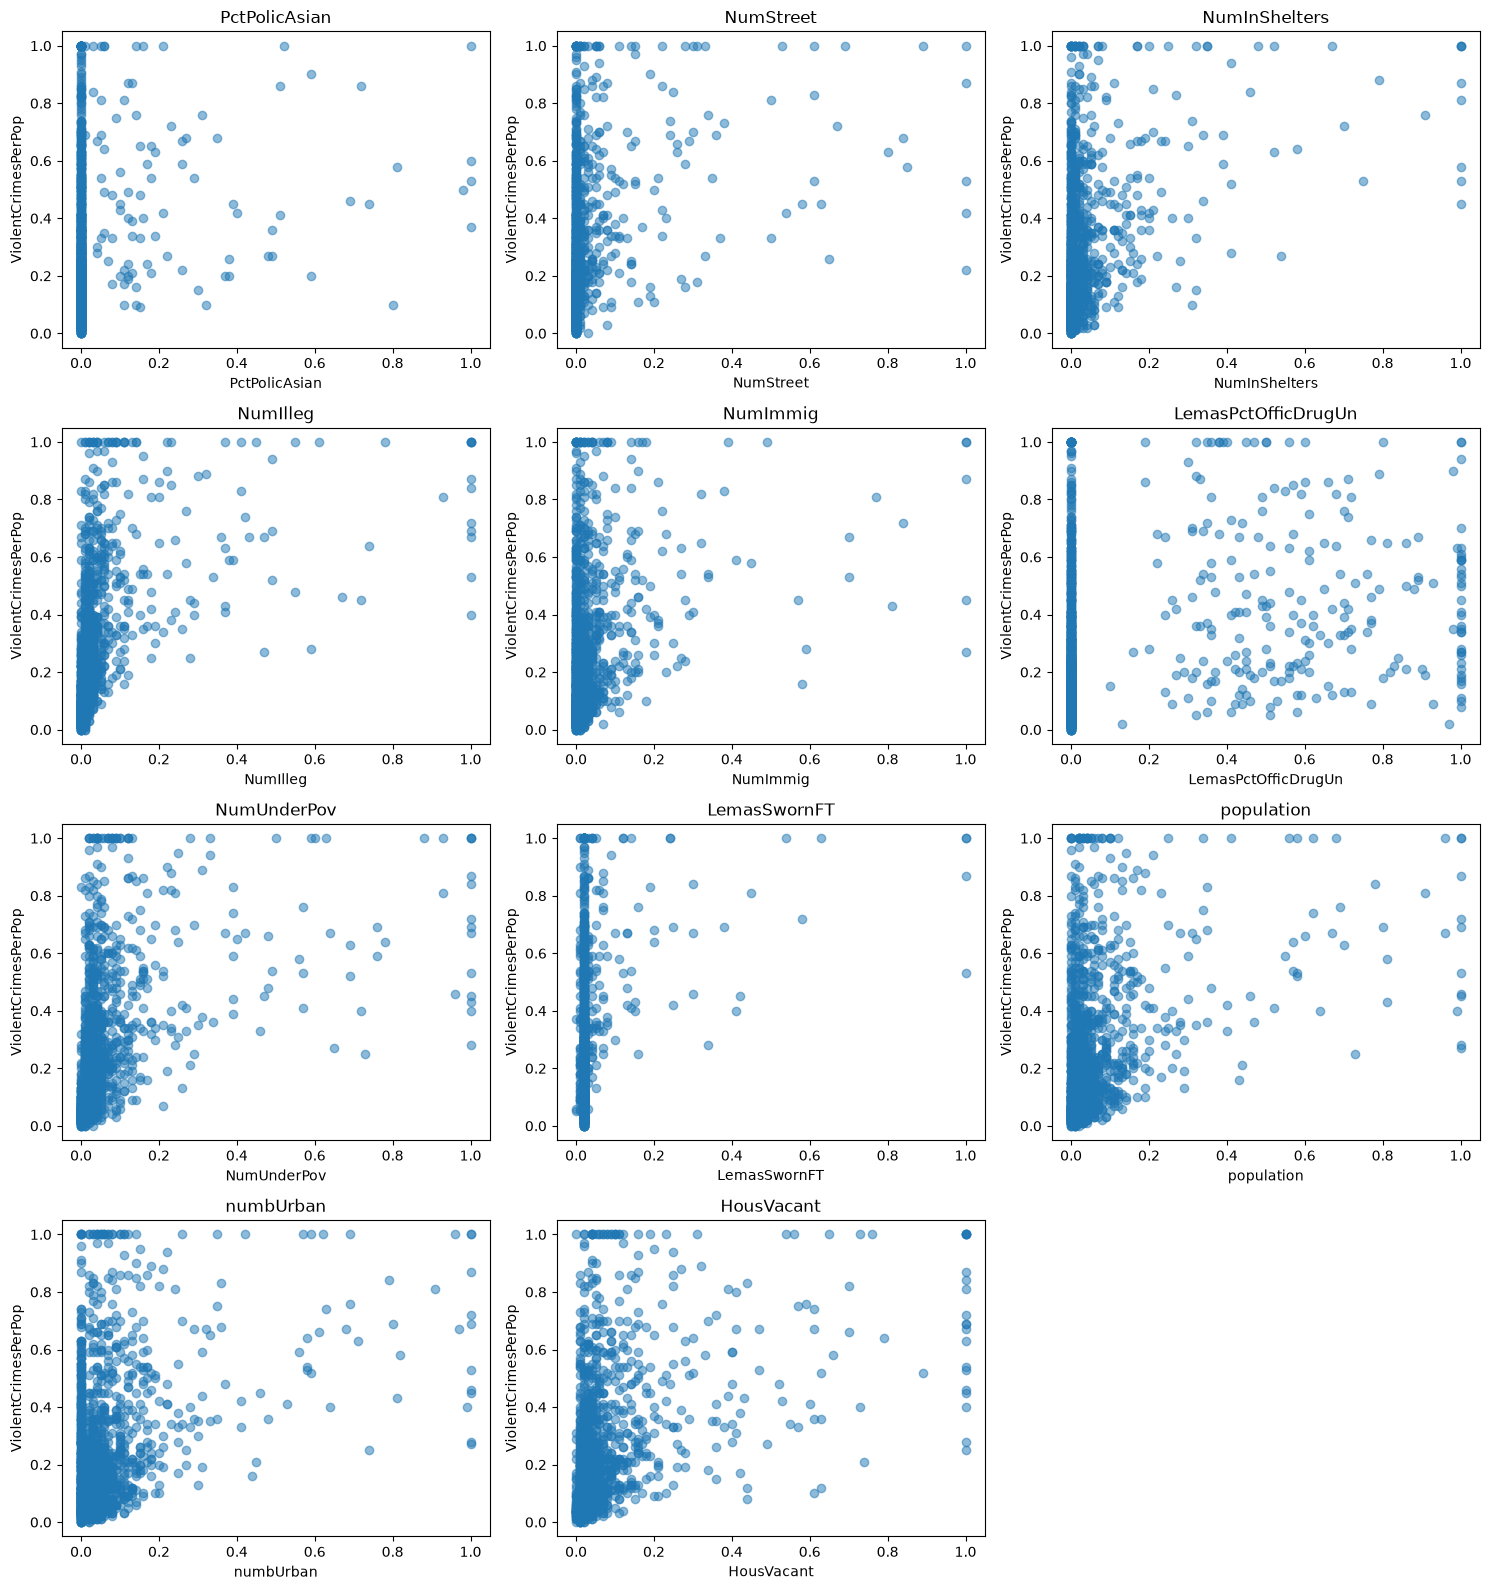

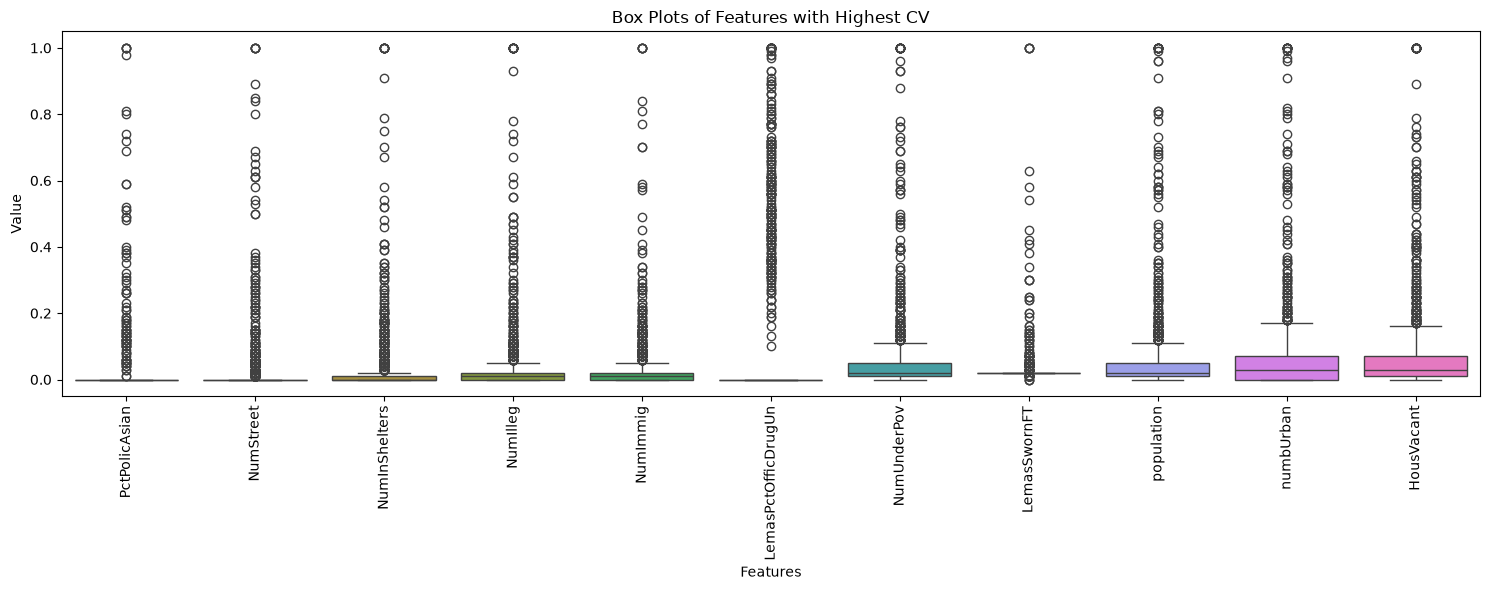

In [52]:
top_features = cv_df.head(11)["Feature"].tolist()

print(cv_df.head(11).to_string(index = False))

fig, axes = plt.subplots(4, 3, figsize = (15, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(X_train[feature], y_train, alpha=0.5)
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

for i in range(len(top_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

plt.figure(figsize = (15, 6))
sns.boxplot(data=X_train[top_features])

plt.xticks(rotation = 90)
plt.title("Box Plots of Features with Highest CV")
plt.xlabel("Features")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

### (f) Fit a linear model

In [53]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred)

print("Linear Regression Test MSE:", linear_mse)

Linear Regression Test MSE: 0.017966215426067342


### (g) Fit a ridge regression model

In [54]:
alphas = np.logspace(-4, 4, 100)
ridge_model = RidgeCV(alphas=alphas, cv=5)
ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)
ridge_mse = mean_squared_error(y_test, ridge_pred)

print("Best lambda:", ridge_model.alpha_)
print("Ridge Regression Test MSE:", ridge_mse)

Best lambda: 2.310129700083163
Ridge Regression Test MSE: 0.017516249302564877


### (h) Fit a LASSO model

In [55]:
lasso_model = LassoCV(cv = 5, random_state = 31, max_iter = 100000)
lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)
lasso_mse = mean_squared_error(y_test, lasso_pred)

lasso_features = X_train.columns[lasso_model.coef_ != 0]

print("Best lambda:", lasso_model.alpha_)
print("LASSO Test MSE:", lasso_mse)
print("Number of selected variables:", len(lasso_features))
print("Selected variables:", lasso_features.tolist())

Best lambda: 0.00012454087437758517
LASSO Test MSE: 0.017617760569778627
Number of selected variables: 74
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'M

In [57]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso_scaled = LassoCV(cv = 5, random_state = 31, max_iter = 100000)
lasso_scaled.fit(X_train_scaled, y_train)

lasso_scaled_pred = lasso_scaled.predict(X_test_scaled)
lasso_scaled_mse = mean_squared_error(y_test, lasso_scaled_pred)

lasso_scaled_features = X_train.columns[lasso_scaled.coef_ != 0]

print("Best lambda:", lasso_scaled.alpha_)
print("Standardized LASSO Test MSE:", lasso_scaled_mse)
print("Number of selected variables:", len(lasso_scaled_features))
print("Selected variables:", lasso_scaled_features.tolist())


Best lambda: 0.0007630833878262516
Standardized LASSO Test MSE: 0.01768200098674982
Number of selected variables: 72
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters

In [59]:
lasso_comparison = pd.DataFrame({
    "Model": ["LASSO", "Standardized LASSO"],
    "Best Lambda": [lasso_model.alpha_, lasso_scaled.alpha_],
    "Test MSE": [lasso_mse, lasso_scaled_mse],
    "Selected Features": [len(lasso_features), len(lasso_scaled_features)]
})

print("LASSO selected variables:")
print(lasso_features.tolist())

print("\nStandardized LASSO selected variables:")
print(lasso_scaled_features.tolist())
print(lasso_comparison)

LASSO selected variables:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameState', 'PctSameC

LASSO regression was fitted using 5-fold cross-validation to select λ. Without standardization, the selected lambda was 0.000125, with a test MSE of 0.017618 and 74 selected features.

After standardizing the features, the selected lambda was 0.000763, with a test MSE of 0.017682 and 72 selected features.

The LASSO model without standardization performed slightly better, although the difference in test MSE was very small. Standardization also resulted in fewer selected features, suggesting a slightly simpler model with similar predictive performance.

### (i) Fit a PCR model

In [61]:
pcr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("regression", LinearRegression())
])

param_grid = {"pca__n_components": range(1, X_train.shape[1] + 1)}

pcr_cv = GridSearchCV(pcr, param_grid, cv = 5, scoring="neg_mean_squared_error")
pcr_cv.fit(X_train, y_train)
print("Best number of components:", pcr_cv.best_params_["pca__n_components"])

pcr_model = pcr_cv.best_estimator_

pcr_pred = pcr_model.predict(X_test)
pcr_mse = mean_squared_error(y_test, pcr_pred)

print("Best M:", pcr_cv.best_params_["pca__n_components"])
print("PCR Test MSE:", pcr_mse)

Best number of components: 95
Best M: 95
PCR Test MSE: 0.018296345367709813


### (j) Fit a boosting tree

Best alpha: 5.455594781168514
Best alpha: 5.455594781168514
XGBoost Test MSE: 0.01715816044041349


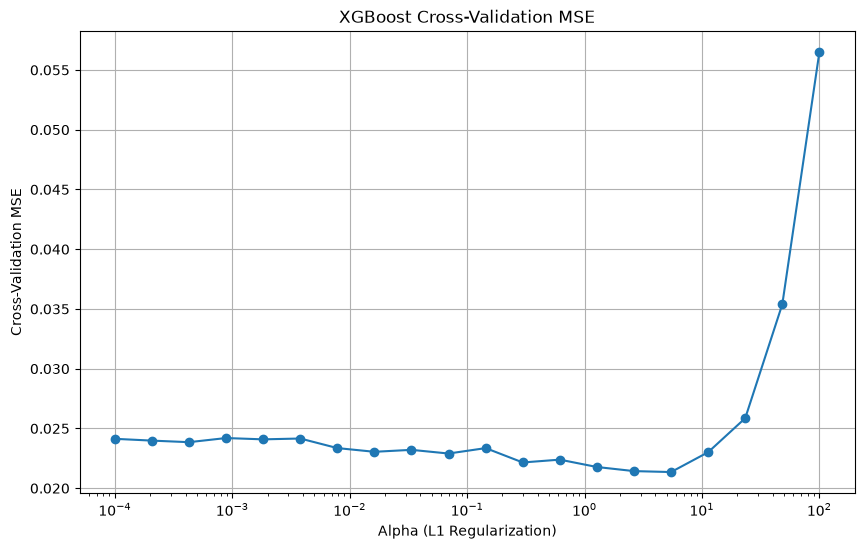

In [64]:
xgb_model = XGBRegressor(objective="reg:squarederror", random_state = 31, n_jobs = 1)

param_grid = {"reg_alpha": np.logspace(-4, 2, 20)}

xgb_cv = GridSearchCV(xgb_model, param_grid, cv = 5, scoring = "neg_mean_squared_error", n_jobs = -1)

xgb_cv.fit(X_train, y_train)

print("Best alpha:", xgb_cv.best_params_["reg_alpha"])

xgb_best = xgb_cv.best_estimator_

xgb_pred = xgb_best.predict(X_test)
xgb_mse = mean_squared_error(y_test, xgb_pred)

print("Best alpha:", xgb_cv.best_params_["reg_alpha"])
print("XGBoost Test MSE:", xgb_mse)

cv_mse = -xgb_cv.cv_results_["mean_test_score"]
alphas = xgb_cv.cv_results_["param_reg_alpha"].data.astype(float)

plt.figure(figsize = (10, 6))
plt.semilogx(alphas, cv_mse, marker = "o")

plt.xlabel("Alpha (L1 Regularization)")
plt.ylabel("Cross-Validation MSE")
plt.title("XGBoost Cross-Validation MSE")
plt.grid(True)
plt.show()
